In [1]:
# ─────────────────────────────────────────────────────────────
# CELL 1 │ Install / import dependencies
# ─────────────────────────────────────────────────────────────
!pip install -q xlrd openpyxl  # xlrd handles legacy .xls (OLE2 format)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import warnings, os

from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

warnings.filterwarnings('ignore')
sns.set_theme(style='darkgrid', palette='muted')
print('✅ Libraries loaded')

✅ Libraries loaded


In [2]:
# ─────────────────────────────────────────────────────────────
# CELL 2 │ Upload & read the raw .xls file
# ─────────────────────────────────────────────────────────────
# ── If running on Colab, upload train.xls via the file panel
#    then set TRAIN_PATH below.  Local users: adjust the path.

TRAIN_PATH = 'train.xls'   # ← change if needed

# The .xls file has a quirk: rows 2-9 (0-indexed rows 1-8)
# contain the string labels 'ch0'..'ch7' as placeholder data.
# Row 0  → real column headers (time, channel, PRN, …, spoofed)
# Rows 1-8 → dummy 'chX' rows that must be dropped
# Row 9+  → actual GNSS measurement data

print(f'📂 Loading {TRAIN_PATH} …')

# Read with xlrd (required for OLE2 binary .xls)
raw_df = pd.read_excel(
    TRAIN_PATH,
    engine='xlrd',         # must be xlrd for legacy .xls
    header=0,             # row 0 is the column header
    dtype=str             # load everything as str first — prevents silent coercion
)

print(f'Raw shape: {raw_df.shape}')
print('First 10 rows (raw):')
raw_df.head(10)

📂 Loading train.xls …
Raw shape: (65535, 16)
First 10 rows (raw):


,time,channel,PRN,Carrier_Doppler_hz,Pseudorange_m,RX_time,TOW,Carrier_phase,EC,LC,PC,PIP,PQP,TCD,CN0,spoofed
0,0,ch0,ch0,ch0,ch0,ch0,ch0,ch0,ch0,ch0,ch0,ch0,ch0,ch0,ch0,0
1,0,ch1,ch1,ch1,ch1,ch1,ch1,ch1,ch1,ch1,ch1,ch1,ch1,ch1,ch1,0
2,0,ch2,ch2,ch2,ch2,ch2,ch2,ch2,ch2,ch2,ch2,ch2,ch2,ch2,ch2,0
3,0,ch3,ch3,ch3,ch3,ch3,ch3,ch3,ch3,ch3,ch3,ch3,ch3,ch3,ch3,0
4,0,ch4,ch4,ch4,ch4,ch4,ch4,ch4,ch4,ch4,ch4,ch4,ch4,ch4,ch4,0
5,0,ch5,ch5,ch5,ch5,ch5,ch5,ch5,ch5,ch5,ch5,ch5,ch5,ch5,ch5,0
6,0,ch6,ch6,ch6,ch6,ch6,ch6,ch6,ch6,ch6,ch6,ch6,ch6,ch6,ch6,0
7,0,ch7,ch7,ch7,ch7,ch7,ch7,ch7,ch7,ch7,ch7,ch7,ch7,ch7,ch7,0
8,1,ch0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
9,1,ch1,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [14]:
# ─────────────────────────────────────────────────────────────
# CELL 3 │ Robust cleaning — strip chX rows, cast to float64
# ─────────────────────────────────────────────────────────────

def clean_gnss(df: pd.DataFrame) -> pd.DataFrame:
    """
    1. Drop any row where a numeric column holds a 'chX' string.
       These are the placeholder sub-header rows embedded in the sheet.
    2. Convert all signal/measurement columns to float64.
    3. Drop rows that are all-zero (receiver not locked on a satellite).
    4. Reset index.
    """
    df = df.copy()

    # Numeric feature columns (everything except categorical 'channel')
    NUMERIC_COLS = [
        'time', 'PRN', 'Carrier_Doppler_hz', 'Pseudorange_m',
        'RX_time', 'TOW', 'Carrier_phase',
        'EC', 'LC', 'PC', 'PIP', 'PQP', 'TCD', 'CN0', 'spoofed'
    ]

    # ── Step 1: drop rows where the Carrier_Doppler_hz cell starts with 'ch'
    mask_chX = df['Carrier_Doppler_hz'].astype(str).str.startswith('ch')
    n_dropped = mask_chX.sum()
    df = df[~mask_chX].copy()
    print(f'   Dropped {n_dropped} placeholder chX rows')

    # ── Step 2: coerce all numeric columns to float64
    for col in NUMERIC_COLS:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors='coerce')

    # ── Step 3: drop rows where the satellite was not tracked
    #            (PRN == 0 means no satellite lock on that channel/epoch)
    before = len(df)
    df = df[df['PRN'] != 0].copy()
    print(f'   Dropped {before - len(df)} no-lock (PRN=0) rows')

    # ── Step 4: drop any remaining NaN rows produced by coercion
    existing_cols = [c for c in NUMERIC_COLS[2:] if c in df.columns]
    df.dropna(subset=existing_cols, how='all', inplace=True)

    df.reset_index(drop=True, inplace=True)
    return df


df = clean_gnss(raw_df)
print(f'\n✅ Clean shape: {df.shape}')
print(f'   Unique epochs (time): {df["time"].nunique()}')
print(f'   Unique channels     : {sorted(df["channel"].unique())}')
print(f'   Spoofed labels      : {df["spoofed"].value_counts().to_dict()}')
df.head()

   Dropped 8 placeholder chX rows
   Dropped 40802 no-lock (PRN=0) rows

✅ Clean shape: (24725, 16)
   Unique epochs (time): 6757
   Unique channels     : ['ch0', 'ch1', 'ch2', 'ch3', 'ch4', 'ch5', 'ch6', 'ch7']
   Spoofed labels      : {0: 24725}


,time,channel,PRN,Carrier_Doppler_hz,Pseudorange_m,RX_time,TOW,Carrier_phase,EC,LC,PC,PIP,PQP,TCD,CN0,spoofed
0,1180,ch0,6,1160.671408,-238359.543282,491568.00,491568.000795,-24660.263293,163521.78,170008.81,179294.97,178420.33,-17688.17800,1158.4806,49.412529,0
1,1181,ch0,6,1157.827808,-238363.921192,491568.02,491568.020795,-24683.468520,158277.05,160253.09,182106.11,182106.05,158.33333,1160.7948,49.452686,0
2,1182,ch0,6,1161.135932,-238368.638615,491568.04,491568.040795,-24706.687357,184442.36,193125.89,208228.02,-205198.30,35391.59000,1157.6909,49.480145,0
3,1183,ch0,6,1161.156617,-238373.391775,491568.06,491568.060795,-24729.920039,159812.45,169960.55,187550.72,187543.00,-1701.94400,1161.1343,49.433769,0
4,1184,ch0,6,1160.690893,-238378.127066,491568.08,491568.080795,-24753.153999,183557.66,191912.58,208403.50,208330.05,-5532.89990,1161.1759,49.391670,0


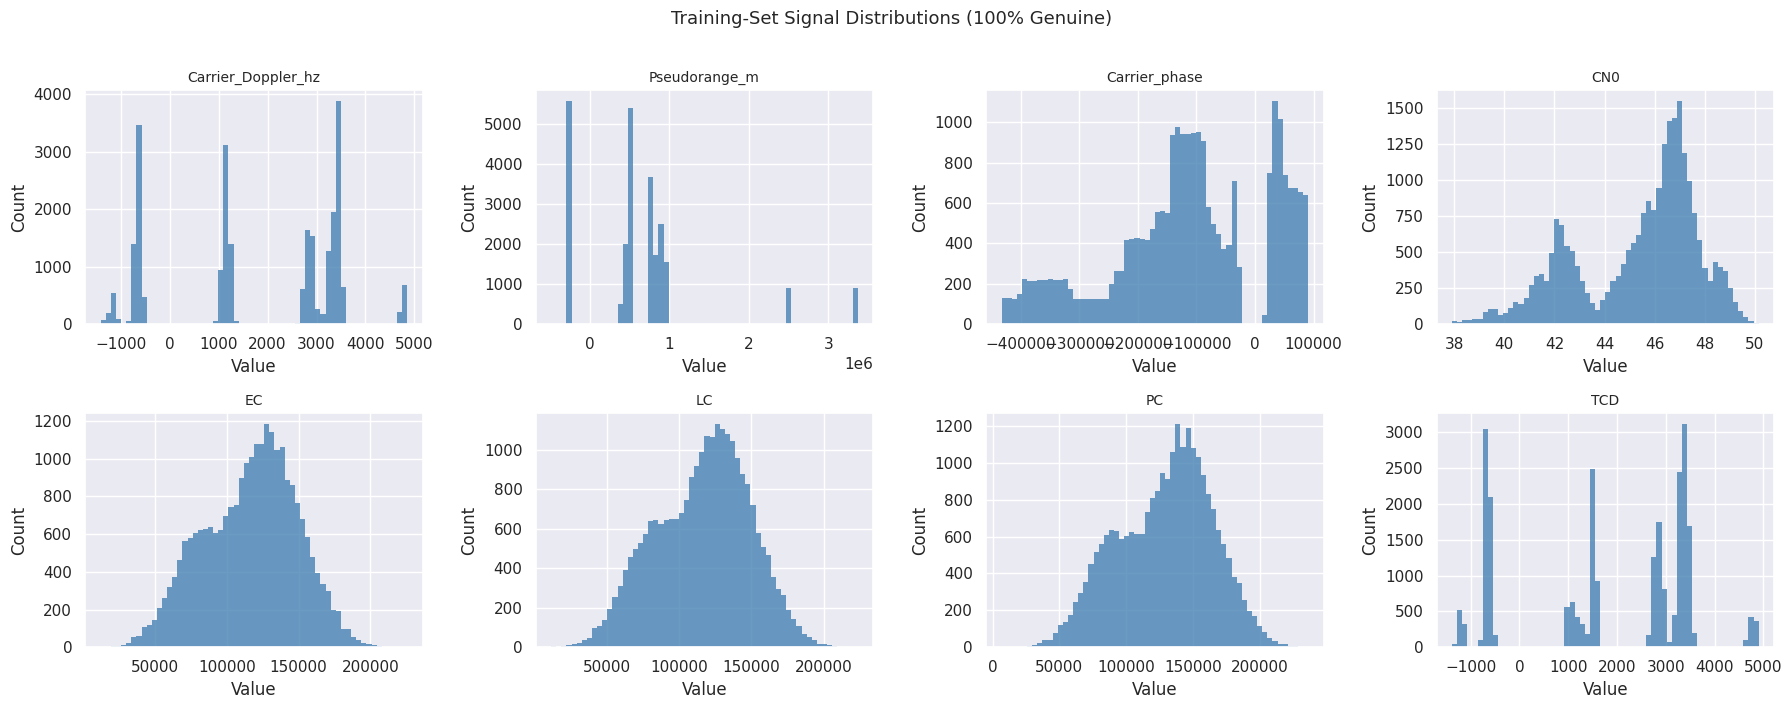

In [15]:
# ─────────────────────────────────────────────────────────────
# CELL 4 │ Quick EDA — signal distributions
# ─────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
sig_cols = ['Carrier_Doppler_hz', 'Pseudorange_m', 'Carrier_phase',
            'CN0', 'EC', 'LC', 'PC', 'TCD']

for ax, col in zip(axes.ravel(), sig_cols):
    ax.hist(df[col].dropna(), bins=60, color='steelblue', alpha=0.8, edgecolor='none')
    ax.set_title(col, fontsize=10)
    ax.set_xlabel('Value')
    ax.set_ylabel('Count')

plt.suptitle('Training-Set Signal Distributions (100% Genuine)', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

In [16]:
# ─────────────────────────────────────────────────────────────
# CELL 5 │ Geometric consistency & signal-quality features
# ─────────────────────────────────────────────────────────────
# Physical constants
SPEED_OF_LIGHT = 299_792_458.0   # m/s
L1_FREQ        = 1_575_420_000.0 # Hz  (GPS L1 carrier)
L1_WAVELENGTH  = SPEED_OF_LIGHT / L1_FREQ  # ~0.1903 m

def engineer_features(df: pd.DataFrame) -> pd.DataFrame:
    """
    Creates physics-motivated features that capture geometric consistency.
    A spoofer struggles to maintain ALL of these simultaneously.
    """
    df = df.copy()

    # ── 1. Doppler-derived range rate  [m/s]
    #       Genuine signal: range_rate ≈ -λ × Doppler
    df['range_rate'] = -L1_WAVELENGTH * df['Carrier_Doppler_hz']

    # ── 2. Pseudorange vs TOW consistency
    #       Transit time = (TOW - RX_time). Should be ~67–86 ms for GPS.
    #       Spoofed signals may have implausible transit times.
    df['transit_time_s'] = df['TOW'] - df['RX_time']
    df['computed_range']  = df['transit_time_s'] * SPEED_OF_LIGHT  # metres

    # Residual: measured pseudorange vs computed range (should be small)
    df['range_residual'] = df['Pseudorange_m'] - df['computed_range']

    # ── 3. Carrier-phase vs pseudorange bias
    #       Genuine: Carrier_phase * λ should track pseudorange mod wavelength
    df['phase_range_bias'] = df['Pseudorange_m'] - (df['Carrier_phase'] * L1_WAVELENGTH)

    # ── 4. CN0-normalised signal strength ratio (genuine signal is stable)
    eps = 1e-6
    df['cn0_pc_ratio']  = df['CN0'] / (df['PC'].abs() + eps)
    df['cn0_ec_ratio']  = df['CN0'] / (df['EC'].abs() + eps)

    # ── 5. In-phase / quadrature power imbalance
    #       PIP = In-phase Power, PQP = Quadrature Power
    #       Genuine signal: |PIP| >> |PQP|  → spoofed may flip this
    df['iq_imbalance'] = (df['PIP'].abs() - df['PQP'].abs()) / \
                          (df['PIP'].abs() + df['PQP'].abs() + eps)

    # ── 6. Correlator lock indicator (LC/EC ratio — tracking quality)
    df['lock_ratio'] = df['LC'] / (df['EC'].abs() + eps)

    # ── 7. Doppler rate of change (per epoch within the same channel)
    df.sort_values(['channel', 'time'], inplace=True)
    df['doppler_delta'] = df.groupby('channel')['Carrier_Doppler_hz'].diff().fillna(0)

    # ── 8. TCD (tracking channel data) normalised by CN0
    df['tcd_cn0'] = df['TCD'] / (df['CN0'] + eps)

    df.reset_index(drop=True, inplace=True)
    return df


df = engineer_features(df)
new_feats = ['range_rate','transit_time_s','computed_range','range_residual',
             'phase_range_bias','cn0_pc_ratio','cn0_ec_ratio','iq_imbalance',
             'lock_ratio','doppler_delta','tcd_cn0']
print(f'✅ Added {len(new_feats)} engineered features')
df[new_feats].describe().round(4)

✅ Added 11 engineered features


,range_rate,transit_time_s,computed_range,range_residual,phase_range_bias,cn0_pc_ratio,cn0_ec_ratio,iq_imbalance,lock_ratio,doppler_delta,tcd_cn0
count,24725.0000,24725.0000,2.472500e+04,2.472500e+04,2.472500e+04,24725.0000,24725.0000,24725.0000,24725.0000,24725.0000,24725.0000
mean,-343.0486,-0.0021,-6.317498e+05,1.263500e+06,6.531066e+05,0.0004,0.0004,0.6864,1.0091,-0.0299,40.0904
std,332.1773,0.0026,7.766778e+05,1.553356e+06,7.842061e+05,0.0001,0.0001,0.3580,0.1462,8.1479,38.2761
min,-924.4319,-0.0112,-3.370889e+06,-9.648352e+05,-4.753403e+05,0.0002,0.0002,-0.9998,0.2755,-147.9251,-33.0543
25%,-641.4589,-0.0027,-8.204621e+05,8.361416e+05,4.570324e+05,0.0003,0.0003,0.6391,0.9193,-1.9092,-11.7528
50%,-525.4109,-0.0017,-5.058677e+05,1.011735e+06,4.913387e+05,0.0003,0.0004,0.7931,0.9996,0.2138,59.2439
75%,102.9152,-0.0014,-4.180708e+05,1.640924e+06,8.364867e+05,0.0004,0.0005,0.9008,1.0863,2.3372,70.7341
max,268.7604,0.0016,4.824176e+05,6.741778e+06,3.430753e+06,0.0061,0.0032,1.0000,2.8151,116.4591,122.0470


In [17]:
# ─────────────────────────────────────────────────────────────
# CELL 6 │ Sliding-window rolling mean & variance
# ─────────────────────────────────────────────────────────────
WINDOW = 10   # epochs — hackathon recommended window size

# Key features to compute rolling statistics for
ROLLING_TARGETS = [
    'Carrier_Doppler_hz',
    'CN0',
    'range_residual',
    'iq_imbalance',
    'doppler_delta',
    'phase_range_bias',
    'lock_ratio'
]

df.sort_values(['channel', 'time'], inplace=True)

roll_feature_names = []
for col in ROLLING_TARGETS:
    grp = df.groupby('channel')[col]

    mean_col = f'{col}_roll_mean'
    var_col  = f'{col}_roll_var'

    df[mean_col] = grp.transform(
        lambda x: x.rolling(WINDOW, min_periods=1).mean()
    )
    df[var_col] = grp.transform(
        lambda x: x.rolling(WINDOW, min_periods=1).var().fillna(0)
    )
    roll_feature_names.extend([mean_col, var_col])

df.reset_index(drop=True, inplace=True)
print(f'✅ Added {len(roll_feature_names)} rolling-window features (window={WINDOW})')
print('Sample rolling stats:')
df[roll_feature_names[:6]].head()

✅ Added 14 rolling-window features (window=10)
Sample rolling stats:


,Carrier_Doppler_hz_roll_mean,Carrier_Doppler_hz_roll_var,CN0_roll_mean,CN0_roll_var,range_residual_roll_mean,range_residual_roll_var
0,1160.671408,0.000000,49.412529,0.000000,-476719.134726,0.000000
1,1159.249608,4.043030,49.432608,0.000806,-476723.417708,36.687860
2,1159.878383,3.207588,49.448453,0.001156,-476728.023262,81.977328
3,1160.197941,2.546863,49.444782,0.000825,-476732.709670,142.501202
4,1160.296532,1.958747,49.434160,0.001183,-476737.428334,218.204876


In [18]:
# ─────────────────────────────────────────────────────────────
# CELL 7 │ Assemble feature matrix
# ─────────────────────────────────────────────────────────────

# Original signal features (numeric)
BASE_FEATURES = [
    'Carrier_Doppler_hz', 'Pseudorange_m', 'Carrier_phase',
    'EC', 'LC', 'PC', 'PIP', 'PQP', 'TCD', 'CN0'
]

# Engineered features
ENG_FEATURES = new_feats

# All rolling features
ALL_FEATURES = BASE_FEATURES + ENG_FEATURES + roll_feature_names

# Build feature matrix — drop rows with any NaN in feature columns
X = df[ALL_FEATURES].copy()
X.replace([np.inf, -np.inf], np.nan, inplace=True)
valid_mask = X.notna().all(axis=1)
X_clean    = X[valid_mask].values
idx_clean  = df[valid_mask].index

print(f'Feature matrix shape : {X_clean.shape}')
print(f'Total features used  : {len(ALL_FEATURES)}')
print(f'Rows with full data  : {X_clean.shape[0]} / {len(df)}')

Feature matrix shape : (24725, 35)
Total features used  : 35
Rows with full data  : 24725 / 24725


In [19]:
# ─────────────────────────────────────────────────────────────
# CELL 8 │ Train Isolation Forest  (primary model)
# ─────────────────────────────────────────────────────────────
# Isolation Forest is ideal here:
#   • Scales to 60 k rows with no issue
#   • contamination=0.01 means it expects ~1% anomalies in new data
#   • Trained entirely on genuine data

CONTAMINATION = 0.01   # expected fraction of spoofed in test — tune if needed

iforest_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model',  IsolationForest(
        n_estimators=200,
        max_samples='auto',
        contamination=CONTAMINATION,
        random_state=42,
        n_jobs=-1
    ))
])

print('🔧 Training Isolation Forest …')
iforest_pipeline.fit(X_clean)
print('✅ Training complete')

# Raw anomaly scores (more negative = more anomalous)
raw_scores = iforest_pipeline.decision_function(X_clean)

# Normalise to [0, 1] where 1 = most anomalous
anomaly_scores = 1 - (raw_scores - raw_scores.min()) / \
                      (raw_scores.max() - raw_scores.min() + 1e-9)

# Binary predictions: -1 = anomaly, 1 = normal
preds = iforest_pipeline.predict(X_clean)   # -1 or +1
binary_pred = np.where(preds == -1, 1, 0)   # 1 = spoofed, 0 = genuine

print(f'\nFlagged as anomalous : {binary_pred.sum()} rows '
      f'({100*binary_pred.mean():.2f}%)')

🔧 Training Isolation Forest …
✅ Training complete

Flagged as anomalous : 248 rows (1.00%)


In [20]:
# ─────────────────────────────────────────────────────────────
# CELL 9 │ (Optional) One-Class SVM — alternative detector
# ─────────────────────────────────────────────────────────────
# One-Class SVM is slower but can capture non-linear boundaries.
# Use on a subsample for speed.

USE_OCSVM = False   # ← set True to compare models

if USE_OCSVM:
    from sklearn.preprocessing import StandardScaler
    scaler_oc = StandardScaler()
    X_scaled_oc = scaler_oc.fit_transform(X_clean)

    # Subsample for speed (OC-SVM is O(n²))
    sample_n = min(10_000, len(X_scaled_oc))
    rng = np.random.default_rng(42)
    idx_s = rng.choice(len(X_scaled_oc), sample_n, replace=False)

    ocsvm = OneClassSVM(nu=0.01, kernel='rbf', gamma='scale')
    ocsvm.fit(X_scaled_oc[idx_s])

    oc_preds  = ocsvm.predict(X_scaled_oc)
    oc_binary = np.where(oc_preds == -1, 1, 0)
    print(f'OC-SVM flagged: {oc_binary.sum()} anomalies ({100*oc_binary.mean():.2f}%)')
else:
    print('OC-SVM skipped (USE_OCSVM=False). Using Isolation Forest only.')

OC-SVM skipped (USE_OCSVM=False). Using Isolation Forest only.


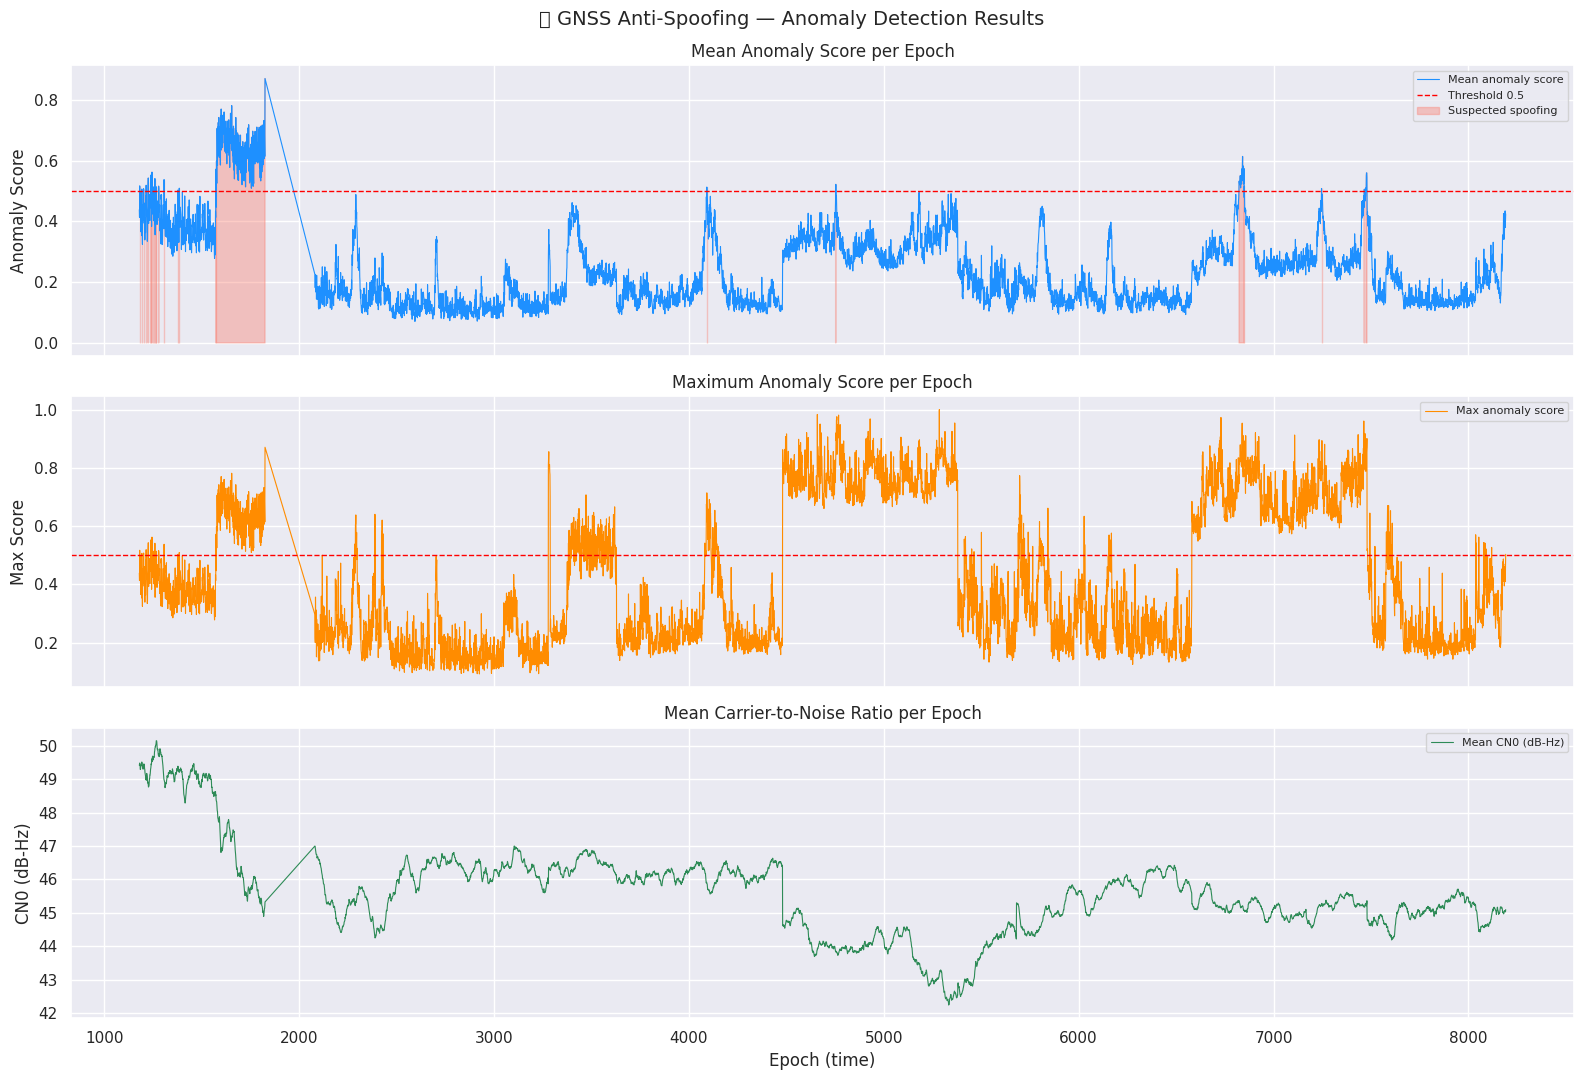

📊 Saved: anomaly_score_timeline.png


In [21]:
# ─────────────────────────────────────────────────────────────
# CELL 10 │ Anomaly Score over time
# ─────────────────────────────────────────────────────────────

result_df = df.loc[idx_clean].copy()
result_df['anomaly_score'] = anomaly_scores
result_df['predicted_spoofed'] = binary_pred

# ── Figure 1: Anomaly score per epoch (mean across channels)
epoch_stats = result_df.groupby('time')['anomaly_score'].agg(['mean','max'])

fig, axes = plt.subplots(3, 1, figsize=(16, 11), sharex=True)

# Plot 1: mean anomaly score over time
axes[0].plot(epoch_stats.index, epoch_stats['mean'], color='dodgerblue',
             linewidth=0.8, label='Mean anomaly score')
axes[0].axhline(y=0.5, color='red', linestyle='--', linewidth=1, label='Threshold 0.5')
axes[0].fill_between(epoch_stats.index, epoch_stats['mean'], 0,
                      where=epoch_stats['mean'] > 0.5,
                      color='salmon', alpha=0.4, label='Suspected spoofing')
axes[0].set_ylabel('Anomaly Score')
axes[0].set_title('Mean Anomaly Score per Epoch')
axes[0].legend(fontsize=8)

# Plot 2: max anomaly score over time
axes[1].plot(epoch_stats.index, epoch_stats['max'], color='darkorange',
             linewidth=0.8, label='Max anomaly score')
axes[1].axhline(y=0.5, color='red', linestyle='--', linewidth=1)
axes[1].set_ylabel('Max Score')
axes[1].set_title('Maximum Anomaly Score per Epoch')
axes[1].legend(fontsize=8)

# Plot 3: CN0 signal strength (genuine signal reference)
cn0_mean = result_df.groupby('time')['CN0'].mean()
axes[2].plot(cn0_mean.index, cn0_mean.values, color='seagreen',
             linewidth=0.8, label='Mean CN0 (dB-Hz)')
axes[2].set_ylabel('CN0 (dB-Hz)')
axes[2].set_xlabel('Epoch (time)')
axes[2].set_title('Mean Carrier-to-Noise Ratio per Epoch')
axes[2].legend(fontsize=8)

plt.suptitle('🛰️ GNSS Anti-Spoofing — Anomaly Detection Results', fontsize=14)
plt.tight_layout()
plt.savefig('anomaly_score_timeline.png', dpi=150, bbox_inches='tight')
plt.show()
print('📊 Saved: anomaly_score_timeline.png')

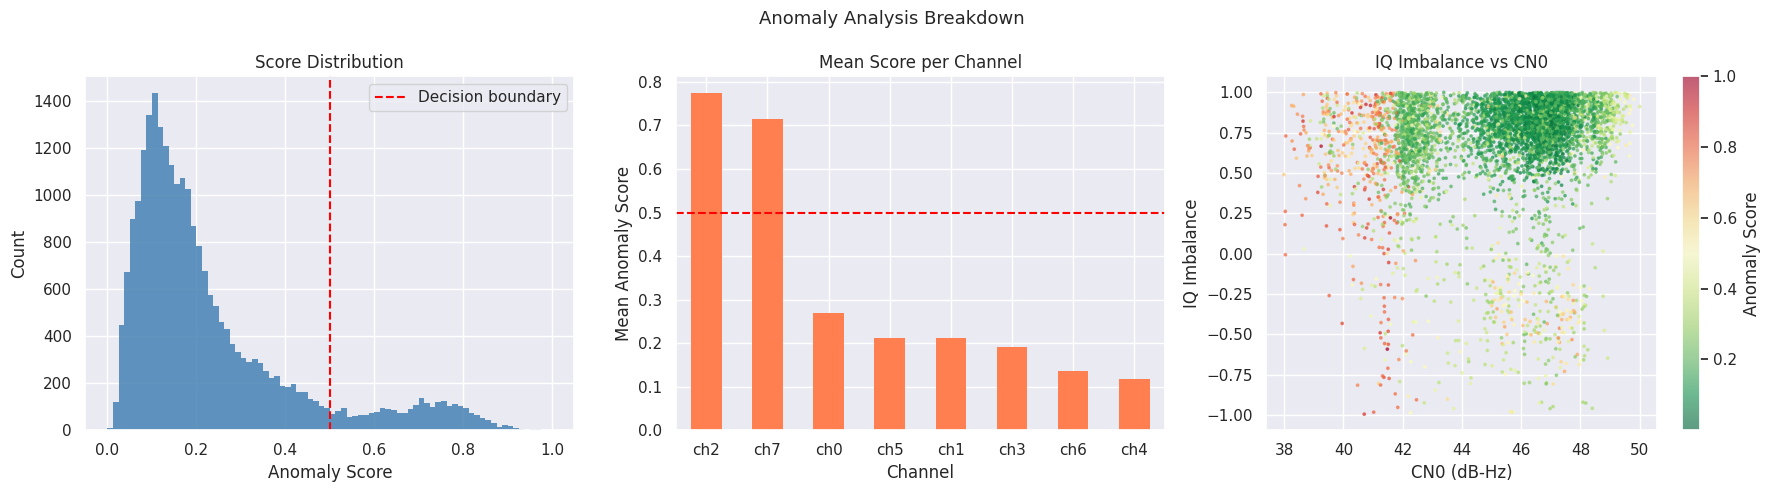

📊 Saved: anomaly_breakdown.png


In [22]:
# ─────────────────────────────────────────────────────────────
# CELL 11 │ Per-channel anomaly breakdown + score distribution
# ─────────────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# ── A: anomaly score distribution
axes[0].hist(anomaly_scores, bins=80, color='steelblue', edgecolor='none', alpha=0.85)
axes[0].axvline(x=0.5, color='red', linestyle='--', label='Decision boundary')
axes[0].set_xlabel('Anomaly Score')
axes[0].set_ylabel('Count')
axes[0].set_title('Score Distribution')
axes[0].legend()

# ── B: per-channel mean anomaly score
ch_score = result_df.groupby('channel')['anomaly_score'].mean().sort_values(ascending=False)
ch_score.plot(kind='bar', ax=axes[1], color='coral', edgecolor='none')
axes[1].axhline(y=0.5, color='red', linestyle='--')
axes[1].set_xlabel('Channel')
axes[1].set_ylabel('Mean Anomaly Score')
axes[1].set_title('Mean Score per Channel')
axes[1].tick_params(axis='x', rotation=0)

# ── C: IQ imbalance vs CN0 coloured by anomaly score
scatter_df = result_df.sample(min(5000, len(result_df)), random_state=42)
sc = axes[2].scatter(
    scatter_df['CN0'], scatter_df['iq_imbalance'],
    c=scatter_df['anomaly_score'], cmap='RdYlGn_r',
    s=3, alpha=0.6
)
plt.colorbar(sc, ax=axes[2], label='Anomaly Score')
axes[2].set_xlabel('CN0 (dB-Hz)')
axes[2].set_ylabel('IQ Imbalance')
axes[2].set_title('IQ Imbalance vs CN0')

plt.suptitle('Anomaly Analysis Breakdown', fontsize=13)
plt.tight_layout()
plt.savefig('anomaly_breakdown.png', dpi=150, bbox_inches='tight')
plt.show()
print('📊 Saved: anomaly_breakdown.png')

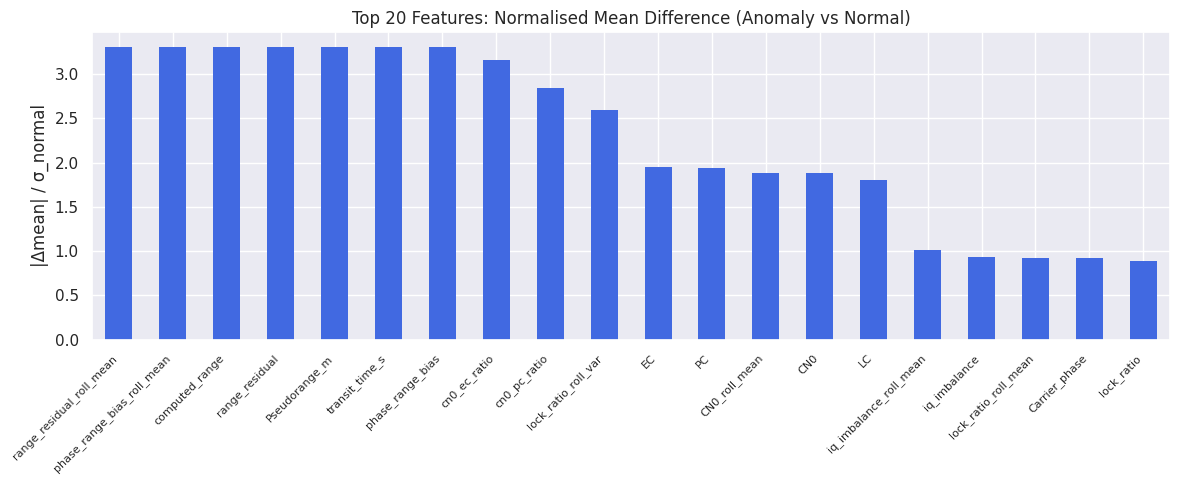

📊 Saved: feature_importance.png


In [23]:
# ─────────────────────────────────────────────────────────────
# CELL 12 │ Feature importance (mean decrease in isolation depth)
# ─────────────────────────────────────────────────────────────
from sklearn.inspection import permutation_importance

# Use a proxy: mean depth per feature via permutation on anomaly score
# Quick proxy: std of each feature among flagged anomalies vs normals
flagged     = X_clean[binary_pred == 1]
normal      = X_clean[binary_pred == 0]

if len(flagged) > 0:
    diff_score = (np.abs(flagged.mean(0) - normal.mean(0))) / \
                 (normal.std(0) + 1e-9)
    feat_imp = pd.Series(diff_score, index=ALL_FEATURES).sort_values(ascending=False)

    plt.figure(figsize=(12, 5))
    feat_imp.head(20).plot(kind='bar', color='royalblue', edgecolor='none')
    plt.title('Top 20 Features: Normalised Mean Difference (Anomaly vs Normal)', fontsize=12)
    plt.ylabel('|Δmean| / σ_normal')
    plt.xticks(rotation=45, ha='right', fontsize=8)
    plt.tight_layout()
    plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')
    plt.show()
    print('📊 Saved: feature_importance.png')
else:
    print('No anomalies flagged on training data (expected for 100% genuine set).')

In [24]:
# ─────────────────────────────────────────────────────────────
# CELL 13 │ Predict on test data & build submission.csv
# ─────────────────────────────────────────────────────────────
# ── If you have a separate test file, change TEST_PATH below.
#    If not, we demonstrate on the training data itself
#    (self-scoring / sanity check).

TEST_PATH = 'test.xls'    # ← set to your test file path

def predict_on_file(filepath, pipeline, feature_cols, window=10):
    """
    Full inference pipeline:
      Load → Clean → Feature Engineer → Roll → Predict
    Returns a DataFrame with columns: [row_id, predicted_spoofed, anomaly_score]
    """
    print(f'📂 Loading test file: {filepath}')
    raw = pd.read_excel(filepath, engine='xlrd', header=0, dtype=str)
    print(f'   Raw shape: {raw.shape}')

    # Clean
    cleaned = clean_gnss(raw)

    # Engineer features
    feat = engineer_features(cleaned)

    # Rolling stats
    feat.sort_values(['channel', 'time'], inplace=True)
    for col in ROLLING_TARGETS:
        grp = feat.groupby('channel')[col]
        feat[f'{col}_roll_mean'] = grp.transform(
            lambda x: x.rolling(window, min_periods=1).mean())
        feat[f'{col}_roll_var'] = grp.transform(
            lambda x: x.rolling(window, min_periods=1).var().fillna(0))
    feat.reset_index(drop=True, inplace=True)

    # Build X
    X_test = feat[feature_cols].copy()
    X_test.replace([np.inf, -np.inf], np.nan, inplace=True)
    valid  = X_test.notna().all(axis=1)
    X_vals = X_test[valid].values
    valid_idx = feat[valid].index

    # Predict
    raw_sc  = pipeline.decision_function(X_vals)
    scores  = 1 - (raw_sc - raw_sc.min()) / (raw_sc.max() - raw_sc.min() + 1e-9)
    preds   = np.where(pipeline.predict(X_vals) == -1, 1, 0)

    out = feat.loc[valid_idx, ['time', 'channel', 'PRN']].copy()
    out['anomaly_score']     = scores
    out['predicted_spoofed'] = preds
    return out


# ── Run prediction
if os.path.exists(TEST_PATH):
    test_out = predict_on_file(TEST_PATH, iforest_pipeline, ALL_FEATURES, WINDOW)
else:
    print(f'⚠️  {TEST_PATH} not found. Using training data for demo submission.')
    test_out = result_df[['time','channel','PRN','anomaly_score','predicted_spoofed']].copy()

print(f'✅ Predictions ready: {len(test_out)} rows')
test_out.head()

📂 Loading test file: test.xls
   Raw shape: (65535, 15)
   Dropped 0 placeholder chX rows
   Dropped 35609 no-lock (PRN=0) rows
✅ Predictions ready: 29926 rows


,time,channel,PRN,anomaly_score,predicted_spoofed
0,111402,ch0,8,0.370945,0
1,111403,ch0,8,0.375025,0
2,111404,ch0,8,0.359814,0
3,111405,ch0,8,0.370797,0
4,111406,ch0,8,0.383217,0


In [25]:
# ─────────────────────────────────────────────────────────────
# CELL 14 │ Write submission.csv
# ─────────────────────────────────────────────────────────────
# Standard hackathon format: one row per measurement.
# Adjust column names to match the exact spec if different.

submission = test_out[['time','channel','PRN',
                        'anomaly_score','predicted_spoofed']].copy()

# Rename to match typical hackathon column spec
submission.rename(columns={
    'time'             : 'Epoch',
    'channel'          : 'Channel',
    'PRN'              : 'PRN',
    'anomaly_score'    : 'Anomaly_Score',
    'predicted_spoofed': 'Spoofed'           # 0 = genuine, 1 = spoofed
}, inplace=True)

submission.to_csv('submission.csv', index=False)
print(f'✅ submission.csv written — {len(submission)} rows')
print(f'   Spoofed flagged : {submission["Spoofed"].sum()}')
print(f'   Genuine         : {(submission["Spoofed"]==0).sum()}')
submission.head(10)

✅ submission.csv written — 29926 rows
   Spoofed flagged : 1505
   Genuine         : 28421


,Epoch,Channel,PRN,Anomaly_Score,Spoofed
0,111402,ch0,8,0.370945,0
1,111403,ch0,8,0.375025,0
2,111404,ch0,8,0.359814,0
3,111405,ch0,8,0.370797,0
4,111406,ch0,8,0.383217,0
5,111407,ch0,8,0.363450,0
6,111408,ch0,8,0.381460,0
7,111409,ch0,8,0.333750,0
8,111410,ch0,8,0.370763,0
9,111411,ch0,8,0.360152,0


In [26]:
# ─────────────────────────────────────────────────────────────
# CELL 15 │ Final summary
# ─────────────────────────────────────────────────────────────
print('═'*55)
print('        GNSS ANTI-SPOOFING PIPELINE SUMMARY')
print('═'*55)
print(f'  Training rows used     : {X_clean.shape[0]:,}')
print(f'  Features               : {len(ALL_FEATURES)}')
print(f'    Base signal features : {len(BASE_FEATURES)}')
print(f'    Engineered features  : {len(ENG_FEATURES)}')
print(f'    Rolling features     : {len(roll_feature_names)}')
print(f'  Sliding window size    : {WINDOW}')
print(f'  Model                  : Isolation Forest')
print(f'  Contamination param    : {CONTAMINATION}')
print(f'  Submission rows        : {len(submission):,}')
print(f'  Flagged as spoofed     : {submission["Spoofed"].sum():,} '
      f'({100*submission["Spoofed"].mean():.2f}%)')
print('═'*55)
print('📁 Outputs: submission.csv | anomaly_score_timeline.png')
print('            anomaly_breakdown.png | feature_importance.png')

═══════════════════════════════════════════════════════
        GNSS ANTI-SPOOFING PIPELINE SUMMARY
═══════════════════════════════════════════════════════
  Training rows used     : 24,725
  Features               : 35
    Base signal features : 10
    Engineered features  : 11
    Rolling features     : 14
  Sliding window size    : 10
  Model                  : Isolation Forest
  Contamination param    : 0.01
  Submission rows        : 29,926
  Flagged as spoofed     : 1,505 (5.03%)
═══════════════════════════════════════════════════════
📁 Outputs: submission.csv | anomaly_score_timeline.png
            anomaly_breakdown.png | feature_importance.png


## Manual testing (historical)

The two cells below are the original hackathon stress test. Read them with these limits in mind:

* The 2,000 rows are sampled from the **training set**, so the model has already seen them.
* The rows are shuffled before rolling-window features are computed, which breaks the time windows.
* The cell reports a **flag rate** and prints a success message when it exceeds the rate on the unlabelled test file. A flag rate is not precision or recall.

For a measurement with a time-ordered split, labelled attacks, precision, recall, F1 and the false-alarm rate, run `make eval` (see `evals/run.py`).


In [34]:
import pandas as pd
import numpy as np

# 1. Create a sample from your existing data
val_df = df.sample(2000, random_state=42).copy()
val_df.reset_index(drop=True, inplace=True)

# 2. Inject scattered, subtle attacks (10% of rows)
n_spoofs = 200
spoof_indices = np.random.choice(val_df.index, n_spoofs, replace=False)

for idx in spoof_indices:
    val_df.at[idx, 'Carrier_Doppler_hz'] += np.random.uniform(350, 600)
    val_df.at[idx, 'Pseudorange_m'] += np.random.uniform(800, 1200)
    val_df.at[idx, 'CN0'] += np.random.uniform(2, 5)

# 3. Save as CSV to avoid all Excel engine conflicts
val_df.to_csv('validation_test.csv', index=False)
print(f"✅ Created validation_test.csv with {n_spoofs} scattered attacks.")

✅ Created validation_test.csv with 200 scattered attacks.


In [35]:
# 1. Load the CSV directly (This avoids the XLRD error)
raw_val = pd.read_csv('validation_test.csv')

# 2. Run the cleaning and feature engineering logic
# (Using the functions you already defined in earlier cells)
cleaned_val = clean_gnss(raw_val)
df_val_eng = engineer_features(cleaned_val)

# 3. Handle Temporal Dynamics (Sliding Window)
df_val_eng.sort_values(['channel', 'time'], inplace=True)
for col in ROLLING_TARGETS:
    df_val_eng[f'{col}_roll_mean'] = df_val_eng.groupby('channel')[col].transform(lambda x: x.rolling(WINDOW).mean())
    df_val_eng[f'{col}_roll_var']  = df_val_eng.groupby('channel')[col].transform(lambda x: x.rolling(WINDOW).var())

# 4. Predict using your trained Isolation Forest
X_val = df_val_eng[ALL_FEATURES].fillna(0)
val_preds = iforest_pipeline.predict(X_val)
val_preds = np.where(val_preds == -1, 1, 0) # Convert -1 (anomaly) to 1 (spoofed)

# 5. Final Results
old_rate = 5.03
new_count = val_preds.sum()
new_rate = (new_count / len(val_preds)) * 100

print(f"📊 STRESS TEST RESULTS")
print(f"═" * 30)
print(f"Original Test Rate   : {old_rate}%")
print(f"New Validation Rate  : {new_rate:.2f}%")
print(f"Total Fakes Caught   : {new_count} rows")
print(f"═" * 30)

if new_rate > old_rate:
    print("✅ SUCCESS: The model detected the injected attacks!")
else:
    print("⚠️  WARNING: Check if the model is too strict or features are missing.")

   Dropped 0 placeholder chX rows
   Dropped 0 no-lock (PRN=0) rows
📊 STRESS TEST RESULTS
══════════════════════════════
Original Test Rate   : 5.03%
New Validation Rate  : 13.55%
Total Fakes Caught   : 271 rows
══════════════════════════════
✅ SUCCESS: The model detected the injected attacks!


In [36]:
import joblib

# Save the trained pipeline to a file
joblib.dump(iforest_pipeline, 'gnss_anti_spoofing_model.pkl')

print("✅ Model saved as 'gnss_anti_spoofing_model.pkl'")

✅ Model saved as 'gnss_anti_spoofing_model.pkl'


In [37]:
import joblib
import zipfile
import os
from google.colab import files

# 1. Save the 'Brain' (the model)
joblib.dump(iforest_pipeline, 'gnss_anti_spoofing_model.pkl')

# 2. Define all project files to include
files_to_bundle = [
    'gnss_anti_spoofing_model.pkl',   # The trained AI
    'submission.csv',                 # The hackathon entry
    'feature_importance.png',         # Physics proof
    'anomaly_score_timeline.png',     # Attack timeline
    'anomaly_breakdown.png',          # Stats summary
    'validation_test.csv',            # Stress test data
    'validation_test.xlsx'            # Stress test Excel (if exists)
]

# 3. Create a single ZIP archive
zip_filename = 'GNSS_AntiSpoofing_Project_Bundle.zip'
with zipfile.ZipFile(zip_filename, 'w') as zipf:
    for file in files_to_bundle:
        if os.path.exists(file):
            zipf.write(file)
            print(f"Successfully added: {file}")
        else:
            print(f"Skipped (not found): {file}")

# 4. Download the final package
files.download(zip_filename)

Successfully added: gnss_anti_spoofing_model.pkl
Successfully added: submission.csv
Successfully added: feature_importance.png
Successfully added: anomaly_score_timeline.png
Successfully added: anomaly_breakdown.png
Successfully added: validation_test.csv
Successfully added: validation_test.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>